# Analisis Sentimen Komentar YouTube Terkait Relokasi Badak Jawa (InSet Lexicon & LSTM)

Notebook ini merupakan versi terstruktur dan telah diperbaiki dari alur analisis sentimen komentar YouTube dengan kata kunci **"Relokasi Badak Jawa"**.

### Tahapan Analisis:
1. **Setup & Konfigurasi**: Instalasi pustaka, pengaturan *seed* reproduktibilitas, dan konstanta global.
2. **Crawling Data YouTube**: Pengambilan daftar video dan komentar menggunakan YouTube Data API v3 (dengan pengelolaan API Key yang aman).
3. **Text Preprocessing**: Pembersihan teks (perbaikan spasi baris baru), *case folding*, tokenisasi, penghapusan *stopword* dengan mempertahankan kata negasi, serta *stemming* Sastrawi yang dioptimalkan.
4. **Pelabelan Otomatis (InSet Lexicon)**: Penentuan skor dan polaritas sentimen (`negative`, `neutral`, `positive`).
5. **Eksplorasi & Visualisasi Data**: Distribusi polaritas, 10 komentar paling positif & negatif, serta *Word Cloud*.
6. **Pemodelan LSTM**: Tokenisasi, pembatasan panjang sekuens (`maxlen=120`), pembagian data terstratifikasi (*stratified split*), *class weighting*, dan pelatihan model LSTM dengan *EarlyStopping*.
7. **Evaluasi Model**: Grafik akurasi & *loss*, *Confusion Matrix*, serta *Classification Report*.

## 1. Setup & Instalasi Dependensi

In [1]:
# Instalasi pustaka tambahan yang diperlukan
%pip install -q Sastrawi wordcloud google-api-python-client

In [2]:
import os
import re
import csv
import random
import string
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from googleapiclient.discovery import build

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences

warnings.filterwarnings("ignore")
pd.options.mode.chained_assignment = None
sns.set(style="whitegrid")

# Konstanta Global & Reproduktibilitas
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

SEARCH_KEYWORD = "relokasi badak jawa"
MAX_VIDEOS = 50
MAX_COMMENTS_PER_VIDEO = 50
MAX_FEATURES = 5000
MAX_LEN = 120

In [3]:
# Unduh resource NLTK yang dibutuhkan
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
print("Setup selesai dan resource NLTK siap digunakan.")

Setup selesai dan resource NLTK siap digunakan.


## 2. Crawling Data Komentar YouTube

> **Catatan Keamanan:** Simpan API Key YouTube Data API v3 Anda di *environment variable* `YOUTUBE_API_KEY` atau di menu **Secrets** Google Colab (jangan menuliskan API Key secara langsung di dalam kode). Jika file CSV hasil *crawling* sudah tersedia, sel di bawah akan langsung memuatnya.

In [4]:
def get_youtube_api_key() -> str:
    """Mengambil API Key dari Colab Secrets atau environment variable."""
    try:
        from google.colab import userdata
        key = userdata.get("YOUTUBE_API_KEY")
        if key:
            return key
    except Exception:
        pass
    return os.environ.get("YOUTUBE_API_KEY", "")


def search_youtube_videos(youtube_client, keyword: str, max_results: int = 50) -> pd.DataFrame:
    """Mencari video YouTube berdasarkan kata kunci (maksimal 50 per permintaan)."""
    request = youtube_client.search().list(
        q=keyword,
        part="snippet",
        type="video",
        maxResults=min(max_results, 50),
        relevanceLanguage="id"
    )
    response = request.execute()

    videos = [
        {
            "Video ID": item["id"]["videoId"],
            "Title": item["snippet"]["title"],
            "Channel": item["snippet"]["channelTitle"],
            "Publish Date": item["snippet"]["publishedAt"],
            "Description": item["snippet"]["description"]
        }
        for item in response.get("items", [])
    ]
    return pd.DataFrame(videos)


def fetch_video_comments(youtube_client, video_ids: list, max_per_video: int = 50) -> pd.DataFrame:
    """Mengambil komentar tingkat atas (top-level comments) dari daftar Video ID."""
    comments_data = []
    disabled_count = 0

    for video_id in video_ids:
        try:
            request = youtube_client.commentThreads().list(
                part="snippet",
                videoId=video_id,
                maxResults=min(max_per_video, 100),
                textFormat="plainText"
            )
            response = request.execute()

            for item in response.get("items", []):
                comment = item["snippet"]["topLevelComment"]["snippet"]
                comments_data.append({
                    "Video ID": video_id,
                    "Author": comment["authorDisplayName"],
                    "Comment": comment["textDisplay"],
                    "Like Count": comment["likeCount"],
                    "Published At": comment["publishedAt"]
                })
        except Exception:
            disabled_count += 1

    print(f"Selesai mengambil {len(comments_data)} komentar ({disabled_count} video menonaktifkan komentar).")
    return pd.DataFrame(comments_data)

In [8]:
RAW_COMMENTS_FILE = "youtube_comments_relokasi_badak_jawa.csv"

if os.path.exists(RAW_COMMENTS_FILE):
    df_comments = pd.read_csv(RAW_COMMENTS_FILE)
    print(f"Memuat dataset lokal '{RAW_COMMENTS_FILE}' dengan {len(df_comments)} komentar.")
else:
    api_key = get_youtube_api_key()
    if not api_key:
        raise ValueError(
            "YOUTUBE_API_KEY belum diatur. Atur melalui Colab Secrets atau os.environ['YOUTUBE_API_KEY']."
        )

    youtube = build("youtube", "v3", developerKey=api_key)
    print(f"Mencari video untuk kata kunci: '{SEARCH_KEYWORD}'...")
    df_youtube = search_youtube_videos(youtube, SEARCH_KEYWORD, max_results=MAX_VIDEOS)
    display(df_youtube.head())

    print("Mengambil komentar dari video yang ditemukan...")
    video_ids = df_youtube["Video ID"].tolist()
    df_comments = fetch_video_comments(youtube, video_ids, max_per_video=MAX_COMMENTS_PER_VIDEO)
    df_comments.to_csv(RAW_COMMENTS_FILE, index=False)

display(df_comments.head())

Mencari video untuk kata kunci: 'relokasi badak jawa'...


,Video ID,Title,Channel,Publish Date,Description
0,G5PHP_uKvEI,"Warga Baduy Tolak Relokasi Badak Jawa, Lembaga...",Tribunnews,2026-11-17T03:59:04Z,Download aplikasi berita TribunX di Play Store...
1,18FIBhmFxTg,7 Tuntutan Aktivis Banten ke Prabowo: Tolak Re...,Tribunnews,2026-11-25T01:14:14Z,Download aplikasi berita TribunX di Play Store...
2,2lsto5SyrtA,"Demo di TN Ujung Kulon, Warga Tolak Wacana Rel...",SINDOnews,2026-11-20T13:12:44Z,Aksi penolakan pemindahan badak Jawa digelar r...
3,bqu-6c03xhs,Guntur Romli Curigai Rencana Hashim Relokasi B...,Tribunnews,2026-11-16T14:45:11Z,Download aplikasi berita TribunX di Play Store...
4,hZZFrRnp070,Polemik Rencana Relokasi Badak Jawa dari Ujung...,CNN Indonesia,2026-11-16T14:15:26Z,Pemerintah pusat mewacanakan pemindahan sebagi...


Mengambil komentar dari video yang ditemukan...
Selesai mengambil 1925 komentar (0 video menonaktifkan komentar).


,Video ID,Author,Comment,Like Count,Published At
0,G5PHP_uKvEI,@UjangDarsono-l6k,Setuju saya juga menolak sebagai warga Banten ...,0,2026-11-24T10:20:07Z
1,G5PHP_uKvEI,@zikrysaeff6936,"Jgn diganggu habitatnya bos, itu kan dari sebe...",0,2026-11-23T12:27:34Z
2,G5PHP_uKvEI,@pudjisubagio5972,setuju dg masyarakat baduy...✊🇮🇩🇵🇸,0,2026-11-23T05:18:02Z
3,G5PHP_uKvEI,@muryanimuzid8098,Tolak tolak tolak,0,2026-11-23T02:11:27Z
4,G5PHP_uKvEI,@greatmasmif,Badak yg masih bertahan itu cuma di ujung kulo...,0,2026-11-22T16:38:25Z


## 3. Text Preprocessing

Perbaikan yang diterapkan pada tahap ini:
* **Perbaikan baris baru (`\n`)**: Mengganti karakter baris baru dengan spasi (`' '`) agar kata di akhir baris tidak menyatu dengan kata di baris berikutnya.
* **Preservasi kata negasi**: Kata seperti `tidak`, `bukan`, `jangan`, `belum`, `gak`, dan `nggak` dipertahankan dari penghapusan *stopword* agar makna sentimen tidak berbalik.
* **Optimasi Stemmer**: Objek `StemmerFactory` diinisialisasi satu kali di luar fungsi agar proses *stemming* berjalan jauh lebih cepat.

In [9]:
# Inisialisasi Stopwords (dengan pengecualian kata negasi) dan Stemmer Sastrawi
negation_words = {
    "tidak", "tak", "tiada", "bukan", "jangan", "belum", "tanpa",
    "kurang", "gak", "ga", "nggak", "enggak", "gk", "tdk", "bkn"
}

nltk_stopwords = set(stopwords.words("indonesian"))
sastrawi_stopwords = set(StopWordRemoverFactory().get_stop_words())
custom_stopwords = (nltk_stopwords | sastrawi_stopwords) - negation_words

stemmer = StemmerFactory().create_stemmer()


def clean_text(text: str) -> str:
    """Membersihkan mention, hashtag, URL, angka, tanda baca, dan spasi berlebih."""
    text = str(text)
    text = re.sub(r"@[A-Za-z0-9_.-]+", " ", text)        # Hapus mention
    text = re.sub(r"#[A-Za-z0-9_]+", " ", text)           # Hapus hashtag
    text = re.sub(r"http\S+|www\.\S+", " ", text)      # Hapus URL
    text = re.sub(r"\b(RT|rt)\b", " ", text)            # Hapus RT
    text = re.sub(r"[0-9]+", " ", text)                   # Hapus angka
    text = text.replace("\n", " ").replace("\r", " ")   # Ganti newline dengan spasi
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text


def case_folding(text: str) -> str:
    return text.lower()


def tokenize_text(text: str) -> list:
    return word_tokenize(text)


def remove_stopwords(tokens: list) -> list:
    return [word for word in tokens if word not in custom_stopwords and len(word) > 1]


def stem_tokens(tokens: list) -> list:
    return [stemmer.stem(word) for word in tokens]


def preprocess_pipeline(df: pd.DataFrame) -> pd.DataFrame:
    """Menjalankan seluruh tahapan preprocessing teks secara berurutan."""
    df = df.dropna(subset=["Comment"]).copy()
    df["text_clean"] = df["Comment"].apply(clean_text).apply(case_folding)

    # Hapus komentar kosong atau duplikat
    df = df[df["text_clean"].str.len() > 2]
    df = df.drop_duplicates(subset=["text_clean"]).reset_index(drop=True)

    df["tokens"] = df["text_clean"].apply(tokenize_text)
    df["tokens_filtered"] = df["tokens"].apply(remove_stopwords)
    df["text_preprocessed"] = df["tokens_filtered"].apply(stem_tokens)

    # Hapus baris yang tidak memiliki token tersisa setelah preprocessing
    df = df[df["text_preprocessed"].map(len) > 0].reset_index(drop=True)
    return df

In [10]:
df_comments = preprocess_pipeline(df_comments)
df_comments.to_csv("comment_lengkap.csv", index=False)

print(f"Total komentar bersih siap analisis: {len(df_comments)}")
display(df_comments[["Comment", "text_clean", "text_preprocessed"]].head())

Total komentar bersih siap analisis: 1901


,Comment,text_clean,text_preprocessed
0,Setuju saya juga menolak sebagai warga Banten ...,setuju saya juga menolak sebagai warga banten ...,"[tuju, tolak, warga, banten, deket, baduymenol..."
1,"Jgn diganggu habitatnya bos, itu kan dari sebe...",jgn diganggu habitatnya bos itu kan dari sebel...,"[jgn, ganggu, habitat, bos, lahir, udah, situ,..."
2,setuju dg masyarakat baduy...✊🇮🇩🇵🇸,setuju dg masyarakat baduy✊🇮🇩🇵🇸,"[tuju, dg, masyarakat, baduy]"
3,Tolak tolak tolak,tolak tolak tolak,"[tolak, tolak, tolak]"
4,Badak yg masih bertahan itu cuma di ujung kulo...,badak yg masih bertahan itu cuma di ujung kulo...,"[badak, yg, tahan, ujung, kulon, mana, kagak, ..."


## 4. Pelabelan Sentimen Otomatis (InSet Lexicon)

Menggunakan kamus **Indonesia Sentiment Lexicon (InSet)** (`positive.tsv` dan `negative.tsv`). Jika berkas kamus belum tersedia di direktori kerja, sel di bawah akan mengunduhnya secara otomatis dari repositori GitHub InSet.

In [11]:
INSET_POS_URL = "https://raw.githubusercontent.com/fajri91/InSet/master/positive.tsv"
INSET_NEG_URL = "https://raw.githubusercontent.com/fajri91/InSet/master/negative.tsv"


def ensure_lexicon_files():
    """Memastikan berkas kamus InSet tersedia di direktori kerja."""
    for url, filename in [(INSET_POS_URL, "positive.tsv"), (INSET_NEG_URL, "negative.tsv")]:
        if not os.path.exists(filename):
            print(f"Mengunduh {filename}...")
            urllib.request.urlretrieve(url, filename)


def load_inset_lexicon(tsv_path: str) -> dict:
    """Membaca berkas TSV InSet menjadi dictionary {kata: bobot}."""
    lexicon = {}
    with open(tsv_path, "r", encoding="utf-8") as file:
        reader = csv.reader(file, delimiter="\t")
        for row in reader:
            if len(row) >= 2:
                try:
                    lexicon[row[0].strip().lower()] = int(row[1])
                except ValueError:
                    continue
    return lexicon


ensure_lexicon_files()
lexicon_positive = load_inset_lexicon("positive.tsv")
lexicon_negative = load_inset_lexicon("negative.tsv")
print(f"Kamus dimuat: {len(lexicon_positive)} kata positif, {len(lexicon_negative)} kata negatif.")

Mengunduh positive.tsv...
Mengunduh negative.tsv...
Kamus dimuat: 3607 kata positif, 6606 kata negatif.


In [12]:
def analyze_sentiment_lexicon(tokens: list) -> tuple:
    """Menghitung skor polaritas dan menentukan kelas sentimen berdasarkan InSet Lexicon."""
    score = 0
    for word in tokens:
        if word in lexicon_positive:
            score += lexicon_positive[word]
        if word in lexicon_negative:
            score += lexicon_negative[word]

    if score > 0:
        polarity = "positive"
    elif score < 0:
        polarity = "negative"
    else:
        polarity = "neutral"

    return score, polarity


results = df_comments["text_preprocessed"].apply(analyze_sentiment_lexicon)
df_comments["polarity_score"] = [res[0] for res in results]
df_comments["polarity"] = [res[1] for res in results]

df_comments.to_csv("comment_data_clean_polarity.csv", index=False)

print("Distribusi Kelas Sentimen:")
print(df_comments["polarity"].value_counts())

Distribusi Kelas Sentimen:
polarity
negative    1228
neutral      340
positive     333
Name: count, dtype: int64


## 5. Eksplorasi Data & Visualisasi

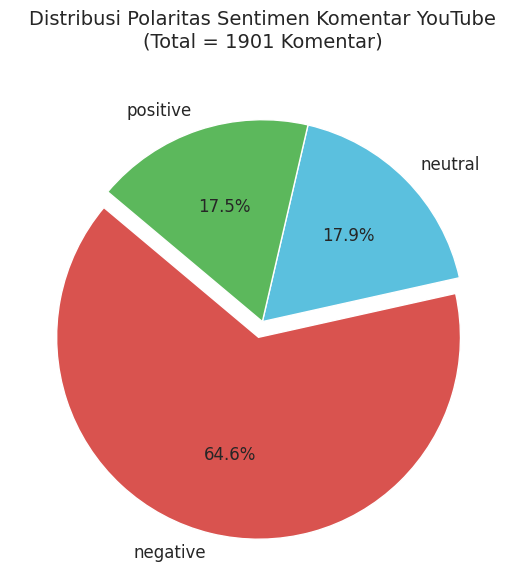

In [13]:
# 5.1 Diagram Lingkaran Distribusi Polaritas Sentimen
polarity_counts = df_comments["polarity"].value_counts()
labels = polarity_counts.index.tolist()
sizes = polarity_counts.values.tolist()
explode = [0.08 if i == 0 else 0 for i in range(len(labels))]

color_map = {"negative": "#d9534f", "neutral": "#5bc0de", "positive": "#5cb85c"}
colors = [color_map.get(lbl, "#777777") for lbl in labels]

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    startangle=140,
    explode=explode,
    colors=colors,
    textprops={"fontsize": 12}
)
ax.set_title(
    f"Distribusi Polaritas Sentimen Komentar YouTube\n(Total = {len(df_comments)} Komentar)",
    fontsize=14,
    pad=16
)
plt.tight_layout()
plt.show()

In [14]:
# 5.2 Top 10 Komentar Paling Positif & Paling Negatif
pd.set_option("display.max_colwidth", 300)

top_positive = (
    df_comments[df_comments["polarity"] == "positive"][["text_clean", "polarity_score", "polarity"]]
    .sort_values(by="polarity_score", ascending=False)
    .head(10)
    .reset_index(drop=True)
)
top_positive.index += 1

top_negative = (
    df_comments[df_comments["polarity"] == "negative"][["text_clean", "polarity_score", "polarity"]]
    .sort_values(by="polarity_score", ascending=True)
    .head(10)
    .reset_index(drop=True)
)
top_negative.index += 1

print("=== TOP 10 KOMENTAR POSITIF ===")
display(top_positive)

print("\n=== TOP 10 KOMENTAR NEGATIF ===")
display(top_negative)

=== TOP 10 KOMENTAR POSITIF ===


,text_clean,polarity_score,polarity
1,terimakasih bu conny pemikiran yg cerdas amanah sesuai al quran jadi alam ini jangan seenaknya direkayasa ingat kerusakan sudah nampak dibumi karena ulah tangan manusia manusia yg dimaksud adlah manusia brengsek yg suka bikin kerusakan klo bhs manusia kita mengerti klo hewan kita ga ngerti ingat...,22,positive
2,mntaf pr ulama mui turun gunung sbb ini adlh bgien jihed ilmu islam kite slelu patuh taet uu tuhan wlw sekelas binatang sbg mkhluk tuhan juge yg brhak hidup jgn trjeda habitatnye trmasuk ibadh sosiel muamalah empati peduli ksh syg kpd smue unsur mkhluk dbumi positifnye ape yg ade dilangit bise k...,20,positive
3,mntap ayo siap banten jngan takut yg punya kanuragan siap petaken pasang rame ayo kumpul yg punya jaya sempurna ilmunya orang banten,17,positive
4,sebagai warga jawa barat saya mengucapkan terima kasih dan apresiasi kepada pak hasyim yang ingin melestarikan badak jawasaya sangat mendukung niat bapakdengan catatan mangga ku bapak panggul hiji badakna pindahkeun langsung ku sorangan pekridho abdi mah pakakod kadinyah badaknahatur nuhun,16,positive
5,wah mantap ini p wagub idenyah luarrr biasa apalagi sampe terlaksana insya allah banten lebih makmur perekonomianyah di bikin kaya di filem dinosourus gituh eh luarrr biasa,14,positive
6,setuju dengan catatan hanya atau pasang yg di relokasi sebagai bagian dari rencana konservasi pelestarian badak jawa kalau sukses bisa dilakukan pola yg sama untuk konservasi badak jawa kedaerah lain pandeglang tetap sebagai pusat yg paling utama pelestarian badak jawa daerah ujung kulon tetap s...,14,positive
7,sejak kapan si kosim peduli sama hewan 😅😅 janji tentang tambahan penghasilan gaji guru saja beliau kadali😢,12,positive
8,ini sangat rakus keliatan aslinya betapa rakusnya dan memanfaatkan jabatan presiden prabowo saudaranya,12,positive
9,jika ulama banten sudah memberi fatwa kami para santrijawara dan masyarakat biasa siap berjihad turun kejalan untuk mempertahankan kedaulatan wilayah pandeglang dan kelestarian alamnya,12,positive
10,badak di pindah apa ada manfaat nya coba manfaat nya apa apa manfaat nya buat pejabat yang rakus apa buat rakyatmasyarakat sekitar,11,positive



=== TOP 10 KOMENTAR NEGATIF ===


,text_clean,polarity_score,polarity
1,saya februari genap tahun 😂 keturunan soekarno itu bukan sumatera tetapi jawa sentris 😂😂😂 belajar lagi yang benar saya fasih minang belanda inggris arab perancis dsb hidup keliling dunia sejak kecil sendirian dan ratarata kalian tidak titel akademis kalian tidak berguna juga buatan para katak da...,-71,negative
2,badak sudah tidak ada di ujung kulon aktifis terakhir tidak bolrh masuk itu sudah menandakan bahwa badak tidak ada di tempat apa lagi aktifitas amfibi masif kalau foto hoak bukti langsung melihat satwa tidak diperbolehkan maka krnyataan berkata badak sudah tidak ada di banten kalian bisa melihat...,-49,negative
3,badak jawa adalah hewan emdemik purba yang sudah jadi simbol ujung kulon memindahkan habitat aslinya ke habitat baru akan memunahkan badak jawa yang kita lindungi beraama kami masyarakat menolak pemindahan hewan endemik purba badak jawa dari ujung kulon masyarakat harus menolak ide yang sangat d...,-49,negative
4,bukan stress nya dimyati coba cek ada apa di balik pemindahan badak itu hasim kan pengusaha dimyati pindahin badak datang alat berat ente mau ngomong apa mau keruk tambang di ujung kulon itu bukan bahasa bijak itu bahasa kompromi wani piro namanya kalo badak di pindahin ngak stress gimana boleh ...,-49,negative
5,luar biasa tidak ada urgensinya luar biasa jelas lahan taman nasional yg dicaplok brutal pake modus paling kotor busuk jahat licik nepotisme brutal jelas kejahatan besarrr ada niat rencana persengkokolan kkn nepotis keluarga jahat serakah sangat wajib digugat,-42,negative
6,badak kalimantan noh di urusin tinggal ekor perempuan terancam punah karna cari cara kek biar ndak punah rekasaya genetik biar bisa hamil bukan bdak jawa yg di ganggu,-39,negative
7,saya harap jangan coba coba mengusik kehidupan ujung kulon biarkan badak tersebut pada tempatnya sebagai warga pandeglang jelas semua akan menolak keras pemindahan tersebut badak ujung kulon adalah badak jawa kuno sebelum adanya suku sunda dimana pun berada dan termasuk badak purba bagi seluruh ...,-38,negative
8,bu titi tolong sampaikan ke pak prabowo ibu yg paham menaklukan kerasnya hati prabowo tolong denger dan lihat rakyat resah semua permasalah bangsa dari badak mau di pindah mbgkopdes dan kebijakan pajak yg menyengsarakan rakyat tolong bu takutnya berita semua hanya sampe mentri penjilat bantu bap...,-36,negative
9,belajar dari bali konsep pariwisata yang dibangun bali itu bukan point a dan point b tetapi dari point a ke point b itu juga pariwisata benahi lingkungan kalian dengan tanaman bunga seni tropical garden dan pohon kelapa burung bebas terbang pasar bersih ajar anak bersih pilah sampah plastik musi...,-36,negative
10,coba coba lo pindah badak ujung kulon banten akan perang terbuka dengan anjing prabowo dan keluarga nya bahlil wajib di bunuh keman pun lo rakyat banten sudah mulai bergerak bantai lo spai gak umurlo pemerintah wajib permen esdm tahun wajib jika tidak rungkadkan prabowo kpu siapkan ulang gak per...,-36,negative


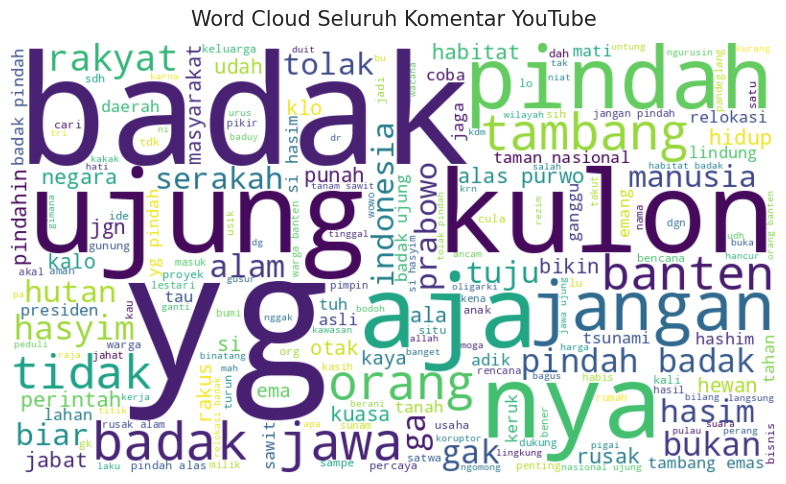

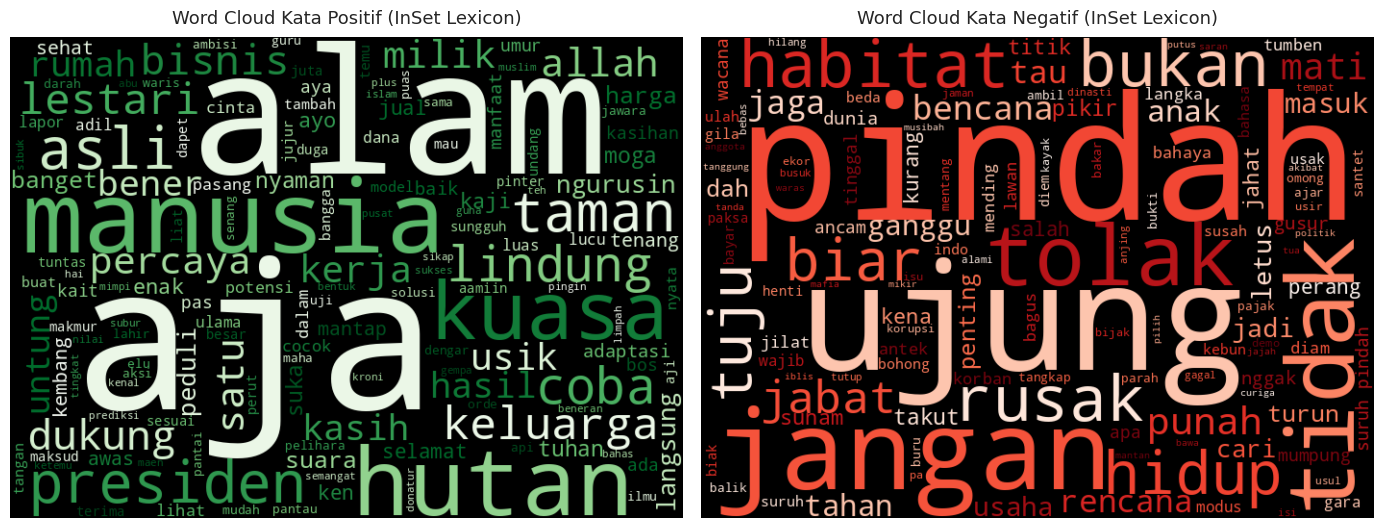

In [15]:
# 5.3 Word Cloud Keseluruhan & Berdasarkan Polaritas Kata
all_words = " ".join(word for tokens in df_comments["text_preprocessed"] for word in tokens)

wc_all = WordCloud(
    width=800,
    height=450,
    background_color="white",
    colormap="viridis",
    min_font_size=10,
    random_state=SEED
).generate(all_words)

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(wc_all, interpolation="bilinear")
ax.set_title("Word Cloud Seluruh Komentar YouTube", fontsize=15, pad=12)
ax.axis("off")
plt.tight_layout()
plt.show()


def extract_sentiment_words(tokens: list) -> tuple:
    pos_words, neg_words = [], []
    for word in tokens:
        word_score = lexicon_positive.get(word, 0) + lexicon_negative.get(word, 0)
        if word_score > 0:
            pos_words.append(word)
        elif word_score < 0:
            neg_words.append(word)
    return pos_words, neg_words


extracted = df_comments["text_preprocessed"].apply(extract_sentiment_words)
positive_corpus = " ".join(w for pair in extracted for w in pair[0])
negative_corpus = " ".join(w for pair in extracted for w in pair[1])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

wc_pos = WordCloud(
    width=700, height=500, background_color="black", colormap="Greens", min_font_size=10, random_state=SEED
).generate(positive_corpus)
axes[0].imshow(wc_pos, interpolation="bilinear")
axes[0].set_title("Word Cloud Kata Positif (InSet Lexicon)", fontsize=13, pad=10)
axes[0].axis("off")

wc_neg = WordCloud(
    width=700, height=500, background_color="black", colormap="Reds", min_font_size=10, random_state=SEED
).generate(negative_corpus)
axes[1].imshow(wc_neg, interpolation="bilinear")
axes[1].set_title("Word Cloud Kata Negatif (InSet Lexicon)", fontsize=13, pad=10)
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 6. Persiapan Data & Pemodelan LSTM

Perbaikan utama pada tahap pemodelan:
1. **Pembatasan panjang sekuens (`maxlen=120`)**: Mencegah komentar *spam* yang sangat panjang memaksa seluruh input diberi *padding* ratusan nol.
2. **Pembagian data terstratifikasi (`stratify=y`)**: Memastikan proporsi kelas `negative`, `neutral`, dan `positive` seimbang antara data latih dan data uji.
3. **Penggunaan `class_weight='balanced'` & `batch_size=32`**: Mengatasi ketimpangan jumlah kelas sehingga model tidak bias ke kelas mayoritas (`negative`) dan meningkatkan *recall* pada kelas `positive`.
4. **Arsitektur Keras 3 bersih (`Input(shape=(MAX_LEN,))`) & `EarlyStopping`**: Menghilangkan peringatan *deprecated* dan menghentikan pelatihan secara otomatis saat `val_loss` berhenti membaik.

In [16]:
# Gabungkan kembali daftar token menjadi kalimat untuk Tokenizer Keras
X_texts = df_comments["text_preprocessed"].apply(lambda tokens: " ".join(tokens))

tokenizer = Tokenizer(num_words=MAX_FEATURES, oov_token="<OOV>")
tokenizer.fit_on_texts(X_texts.values)

X_sequences = tokenizer.texts_to_sequences(X_texts.values)
X = pad_sequences(X_sequences, maxlen=MAX_LEN, padding="post", truncating="post")

# Encode label target
polarity_encode = {"negative": 0, "neutral": 1, "positive": 2}
y = df_comments["polarity"].map(polarity_encode).values

# Split 80% Train, 20% Test dengan stratifikasi kelas
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"Shape X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Shape X_test : {X_test.shape}, y_test : {y_test.shape}")

Shape X_train: (1520, 120), y_train: (1520,)
Shape X_test : (381, 120), y_test : (381,)


In [17]:
# Hitung bobot kelas untuk menangani ketidakseimbangan distribusi sentimen
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))
print("Class weights:", class_weight_dict)


def build_lstm_model(
    vocab_size: int = MAX_FEATURES,
    embed_dim: int = 64,
    lstm_units: int = 32,
    dropout_rate: float = 0.3,
    learning_rate: float = 1e-3
) -> Sequential:
    model = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(input_dim=vocab_size, output_dim=embed_dim, mask_zero=True),
        Bidirectional(LSTM(units=lstm_units, activation="tanh")),
        Dropout(dropout_rate),
        Dense(units=32, activation="relu"),
        Dropout(dropout_rate),
        Dense(units=3, activation="softmax")
    ])

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(learning_rate=learning_rate),
        metrics=["accuracy"]
    )
    return model


lstm_model = build_lstm_model()
lstm_model.summary()

Class weights: {np.int64(0): np.float64(0.5159538357094365), np.int64(1): np.float64(1.8627450980392157), np.int64(2): np.float64(1.9047619047619047)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 120, 64)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,011 (1.32 MB)

 Trainable params: 347,011 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

history = lstm_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.15,
    class_weight=class_weight_dict,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - accuracy: 0.5820 - loss: 1.0790 - val_accuracy: 0.6009 - val_loss: 1.0576
Epoch 2/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.6788 - loss: 1.0000 - val_accuracy: 0.5833 - val_loss: 0.9178
Epoch 3/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 6s 86ms/step - accuracy: 0.8398 - loss: 0.7510 - val_accuracy: 0.5746 - val_loss: 1.0423
Epoch 4/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.9350 - loss: 0.4471 - val_accuracy: 0.6360 - val_loss: 1.0085
Epoch 5/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - accuracy: 0.9752 - loss: 0.2098 - val_accuracy: 0.6711 - val_loss: 1.1855
Epoch 6/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.9752 - loss: 0.1497 - val_accuracy: 0.7105 - val_loss: 1.0342
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 2.


## 7. Evaluasi Model

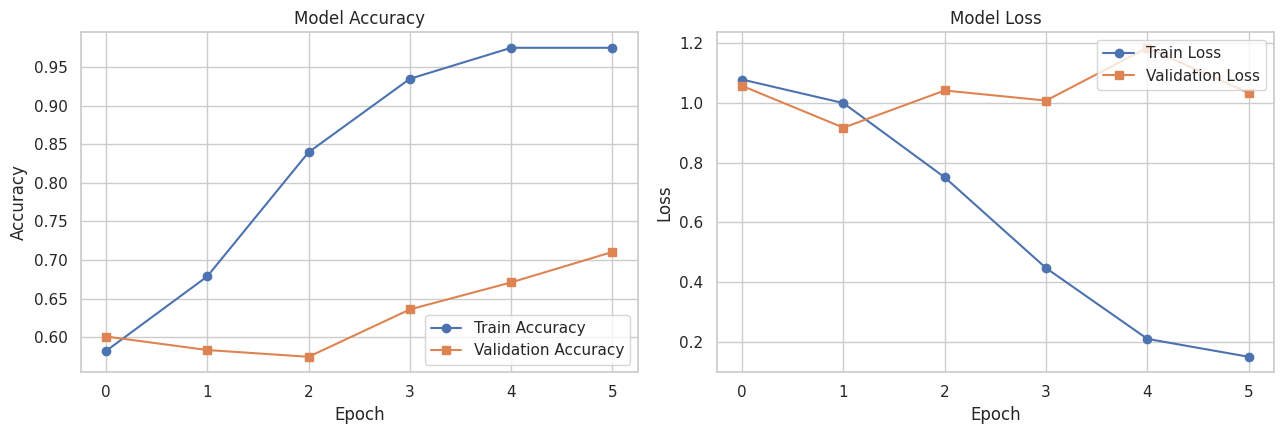

In [19]:
# 7.1 Visualisasi Kurva Akurasi & Loss Selama Pelatihan
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history.history["accuracy"], label="Train Accuracy", marker="o")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy", marker="s")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="lower right")

axes[1].plot(history.history["loss"], label="Train Loss", marker="o")
axes[1].plot(history.history["val_loss"], label="Validation Loss", marker="s")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step
Akurasi Model pada Data Uji: 0.6824 (68.24%)

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

Negative (0)       0.82      0.79      0.80       246
 Neutral (1)       0.81      0.44      0.57        68
Positive (2)       0.34      0.54      0.41        67

    accuracy                           0.68       381
   macro avg       0.66      0.59      0.60       381
weighted avg       0.73      0.68      0.69       381



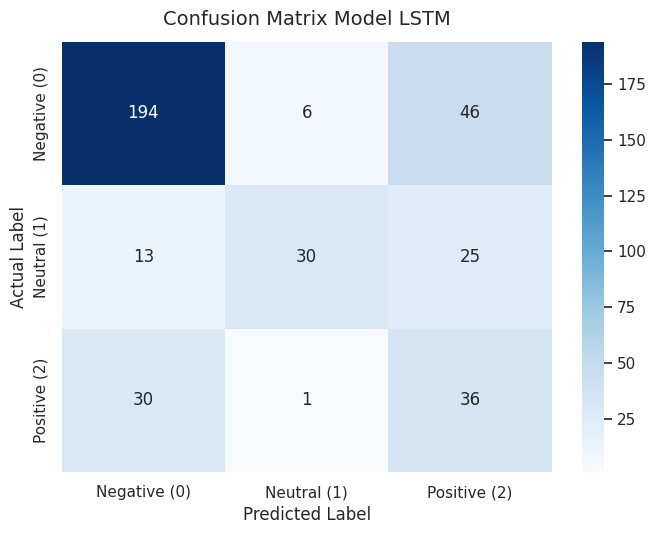

In [20]:
# 7.2 Prediksi Data Uji, Confusion Matrix, dan Classification Report
y_pred_probs = lstm_model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi Model pada Data Uji: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)\n")

target_names = ["Negative (0)", "Neutral (1)", "Positive (2)"]
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=target_names))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names,
    ax=ax
)
ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("Actual Label", fontsize=12)
ax.set_title("Confusion Matrix Model LSTM", fontsize=14, pad=12)
plt.tight_layout()
plt.show()